# Imports

In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from typing import TypedDict
from dotenv import load_dotenv
import os

# Loading env variables

In [2]:
load_dotenv()

True

# Define LLM

In [3]:
model = ChatOpenAI(
    model="minimax/minimax-m2.7",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("ROUTER_API_KEY"),
    temperature=0.7,
)

# Define State

In [4]:
class BlogState(TypedDict):

    title: str
    outline: str
    content: str

# Creating Nodes

In [5]:
def create_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    # update state
    state['outline'] = outline

    return state

In [6]:
def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'

    content = model.invoke(prompt).content

    state['content'] = content

    return state

# Define and Compile Graph

In [7]:
graph = StateGraph(BlogState)

# nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

# edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()


# Execute the Graph

In [8]:
intial_state = {'title': 'Rise of AI in India'}

final_state = workflow.invoke(intial_state)

print(final_state)

{'title': 'Rise of AI in India', 'outline': 'Here is a detailed outline for a comprehensive blog post on the **"Rise of AI in India."**\n\nThis outline is structured to take the reader from the foundational governmental policies to the real-world applications and the ethical challenges that follow. It is designed to be approximately 2,000–3,000 words in length.\n\n---\n\n# **Title Idea:** *From the IT Backoffice to the AI Frontier: The Silent Revolution of Artificial Intelligence in India*\n\n---\n\n## **Introduction: The New "IT"**\n*   **The Hook:** Start by contrasting India’s legacy as the world’s IT outsourcing capital (writing code for the West) with its new ambition to become a leader in *AI creation* and *AI application*.\n*   **Context:** Briefly introduce the global AI race and position India as a uniquely placed player due to its data volume, talent pool, and digital infrastructure (e.g., UPI, Aadhaar).\n*   **Thesis Statement:** State that India’s AI story isn’t just about 

In [9]:
print(final_state['outline'])

Here is a detailed outline for a comprehensive blog post on the **"Rise of AI in India."**

This outline is structured to take the reader from the foundational governmental policies to the real-world applications and the ethical challenges that follow. It is designed to be approximately 2,000–3,000 words in length.

---

# **Title Idea:** *From the IT Backoffice to the AI Frontier: The Silent Revolution of Artificial Intelligence in India*

---

## **Introduction: The New "IT"**
*   **The Hook:** Start by contrasting India’s legacy as the world’s IT outsourcing capital (writing code for the West) with its new ambition to become a leader in *AI creation* and *AI application*.
*   **Context:** Briefly introduce the global AI race and position India as a uniquely placed player due to its data volume, talent pool, and digital infrastructure (e.g., UPI, Aadhaar).
*   **Thesis Statement:** State that India’s AI story isn’t just about technology; it’s about solving unique societal problems an

In [10]:
print(final_state['content'])

# From the IT Backoffice to the AI Frontier: The Silent Revolution of Artificial Intelligence in India

## Introduction: The New "IT"

For decades, India has been synonymous with one thing in the global technology landscape—outsourcing. Millions of Indian programmers wrote code for Fortune 500 companies, supported customer service centers for global banks, and maintained the digital infrastructure of corporations thousands of miles away. The phrase "India's IT sector" conjured images of cubicles in Bangalore and Hyderabad where engineers worked through the night to meet the demands of Western clients. India was, in essence, the world's back office.

But something profound is shifting. The same country that built its economic rise on writing code for others is now positioning itself to lead the artificial intelligence revolution. This isn't merely an evolution of India's IT industry—it's a fundamental reimagining of its role in the global technology ecosystem. India is no longer content

# Visualize Graph (Optional)

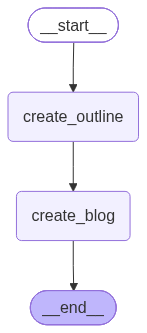

In [11]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())